In [45]:
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pymongo import MongoClient

client = MongoClient("mongodb://localhost:27017")
db = client["penguins_db"]
penguins = client["penguins_db"]["penguins"]
 
penguins.drop()
 
with open("data/penguins_mongo.json", encoding="utf-8") as f:
    tekst = f.read().strip()
 
if tekst.startswith("["):
    dokumenty = json.loads(tekst)
else:
    dokumenty = [json.loads(linia) for linia in tekst.splitlines() if linia.strip()]
 
for d in dokumenty:
    if "culmen_length_mm" in d:
        d["bill_length_mm"] = d.pop("culmen_length_mm")
    if "culmen_depth_mm" in d:
        d["bill_depth_mm"] = d.pop("culmen_depth_mm")
    sex = d.get("sex")
    if isinstance(sex, str) and sex.lower() in ("male", "female"):
        d["sex"] = sex.lower()
    else:
        d["sex"] = None
 
penguins.insert_many(dokumenty)
 
print("Liczba dokumentów:", penguins.count_documents({}))
print("Pole year:", penguins.count_documents({"year": {"$exists": True}}))
print(penguins.find_one())
 

Liczba dokumentów: 344
Pole year: 344
{'_id': ObjectId('6b048b2448b55d050a3015e7'), 'species': 'Adelie', 'island': 'Torgersen', 'bill_length_mm': 39.1, 'bill_depth_mm': 18.7, 'flipper_length_mm': 181, 'body_mass_g': 3750, 'sex': 'male', 'year': 2007}


# Zadanie 1

In [46]:
filtr = {"species": "Chinstrap", "island": "Dream", "body_mass_g": {"$gt": 3500}}
for doc in penguins.find(filtr, {"_id": 0}):
    print(doc)
print("Liczba:", penguins.count_documents(filtr))


{'species': 'Chinstrap', 'island': 'Dream', 'bill_length_mm': 50.0, 'bill_depth_mm': 19.5, 'flipper_length_mm': 196, 'body_mass_g': 3900, 'sex': 'male', 'year': 2007}
{'species': 'Chinstrap', 'island': 'Dream', 'bill_length_mm': 51.3, 'bill_depth_mm': 19.2, 'flipper_length_mm': 193, 'body_mass_g': 3650, 'sex': 'male', 'year': 2007}
{'species': 'Chinstrap', 'island': 'Dream', 'bill_length_mm': 45.4, 'bill_depth_mm': 18.7, 'flipper_length_mm': 188, 'body_mass_g': 3525, 'sex': 'female', 'year': 2007}
{'species': 'Chinstrap', 'island': 'Dream', 'bill_length_mm': 52.7, 'bill_depth_mm': 19.8, 'flipper_length_mm': 197, 'body_mass_g': 3725, 'sex': 'male', 'year': 2007}
{'species': 'Chinstrap', 'island': 'Dream', 'bill_length_mm': 45.2, 'bill_depth_mm': 17.8, 'flipper_length_mm': 198, 'body_mass_g': 3950, 'sex': 'female', 'year': 2007}
{'species': 'Chinstrap', 'island': 'Dream', 'bill_length_mm': 51.3, 'bill_depth_mm': 18.2, 'flipper_length_mm': 197, 'body_mass_g': 3750, 'sex': 'male', 'year': 

In [47]:
cursor = penguins.find(
    {},
    {"species": 1, "island": 1, "bill_length_mm": 1, "_id": 0}
).sort("bill_length_mm", -1).limit(10)
for doc in cursor:
    print(doc)

{'species': 'Gentoo', 'island': 'Biscoe', 'bill_length_mm': 59.6}
{'species': 'Chinstrap', 'island': 'Dream', 'bill_length_mm': 58.0}
{'species': 'Gentoo', 'island': 'Biscoe', 'bill_length_mm': 55.9}
{'species': 'Chinstrap', 'island': 'Dream', 'bill_length_mm': 55.8}
{'species': 'Gentoo', 'island': 'Biscoe', 'bill_length_mm': 55.1}
{'species': 'Gentoo', 'island': 'Biscoe', 'bill_length_mm': 54.3}
{'species': 'Chinstrap', 'island': 'Dream', 'bill_length_mm': 54.2}
{'species': 'Chinstrap', 'island': 'Dream', 'bill_length_mm': 53.5}
{'species': 'Gentoo', 'island': 'Biscoe', 'bill_length_mm': 53.4}
{'species': 'Chinstrap', 'island': 'Dream', 'bill_length_mm': 52.8}


In [48]:
filtr = {"year": 2007, "island": {"$in": ["Torgersen", "Biscoe"]}}
for doc in penguins.find(filtr, {"_id": 0}):
    print(doc)
print("Liczba:", penguins.count_documents(filtr))


{'species': 'Adelie', 'island': 'Torgersen', 'bill_length_mm': 39.1, 'bill_depth_mm': 18.7, 'flipper_length_mm': 181, 'body_mass_g': 3750, 'sex': 'male', 'year': 2007}
{'species': 'Adelie', 'island': 'Torgersen', 'bill_length_mm': 39.5, 'bill_depth_mm': 17.4, 'flipper_length_mm': 186, 'body_mass_g': 3800, 'sex': 'female', 'year': 2007}
{'species': 'Adelie', 'island': 'Torgersen', 'bill_length_mm': 40.3, 'bill_depth_mm': 18.0, 'flipper_length_mm': 195, 'body_mass_g': 3250, 'sex': 'female', 'year': 2007}
{'species': 'Adelie', 'island': 'Torgersen', 'bill_length_mm': None, 'bill_depth_mm': None, 'flipper_length_mm': None, 'body_mass_g': None, 'sex': None, 'year': 2007}
{'species': 'Adelie', 'island': 'Torgersen', 'bill_length_mm': 36.7, 'bill_depth_mm': 19.3, 'flipper_length_mm': 193, 'body_mass_g': 3450, 'sex': 'female', 'year': 2007}
{'species': 'Adelie', 'island': 'Torgersen', 'bill_length_mm': 39.3, 'bill_depth_mm': 20.6, 'flipper_length_mm': 190, 'body_mass_g': 3650, 'sex': 'male', '

In [49]:
for doc in penguins.find({"sex": None}, {"_id": 0}):
    print(doc)
print("Liczba:", penguins.count_documents({"sex": None}))
pipeline = [
    {"$match": {"sex": None}},
    {"$group": {"_id": {"species": "$species", "island": "$island"},
                "count": {"$sum": 1}}},
    {"$sort": {"count": -1}}
]
for doc in penguins.aggregate(pipeline):
    print(doc)

{'species': 'Adelie', 'island': 'Torgersen', 'bill_length_mm': None, 'bill_depth_mm': None, 'flipper_length_mm': None, 'body_mass_g': None, 'sex': None, 'year': 2007}
{'species': 'Adelie', 'island': 'Torgersen', 'bill_length_mm': 34.1, 'bill_depth_mm': 18.1, 'flipper_length_mm': 193, 'body_mass_g': 3475, 'sex': None, 'year': 2007}
{'species': 'Adelie', 'island': 'Torgersen', 'bill_length_mm': 42.0, 'bill_depth_mm': 20.2, 'flipper_length_mm': 190, 'body_mass_g': 4250, 'sex': None, 'year': 2007}
{'species': 'Adelie', 'island': 'Torgersen', 'bill_length_mm': 37.8, 'bill_depth_mm': 17.1, 'flipper_length_mm': 186, 'body_mass_g': 3300, 'sex': None, 'year': 2007}
{'species': 'Adelie', 'island': 'Torgersen', 'bill_length_mm': 37.8, 'bill_depth_mm': 17.3, 'flipper_length_mm': 180, 'body_mass_g': 3700, 'sex': None, 'year': 2007}
{'species': 'Adelie', 'island': 'Dream', 'bill_length_mm': 37.5, 'bill_depth_mm': 18.9, 'flipper_length_mm': 179, 'body_mass_g': 2975, 'sex': None, 'year': 2007}
{'speci

In [50]:

filtr = {"body_mass_g": {"$gte": 3000, "$lte": 3500}}
cursor = penguins.find(
    filtr,
    {"species": 1, "sex": 1, "body_mass_g": 1, "_id": 0}
).sort("body_mass_g", 1)
for doc in cursor:
    print(doc)
print("Liczba:", penguins.count_documents(filtr))

{'species': 'Adelie', 'body_mass_g': 3000, 'sex': 'female'}
{'species': 'Adelie', 'body_mass_g': 3000, 'sex': 'female'}
{'species': 'Adelie', 'body_mass_g': 3050, 'sex': 'female'}
{'species': 'Adelie', 'body_mass_g': 3050, 'sex': 'female'}
{'species': 'Adelie', 'body_mass_g': 3050, 'sex': 'female'}
{'species': 'Adelie', 'body_mass_g': 3050, 'sex': 'female'}
{'species': 'Adelie', 'body_mass_g': 3075, 'sex': 'female'}
{'species': 'Adelie', 'body_mass_g': 3100, 'sex': 'female'}
{'species': 'Adelie', 'body_mass_g': 3150, 'sex': 'female'}
{'species': 'Adelie', 'body_mass_g': 3150, 'sex': 'female'}
{'species': 'Adelie', 'body_mass_g': 3150, 'sex': 'female'}
{'species': 'Adelie', 'body_mass_g': 3150, 'sex': 'female'}
{'species': 'Adelie', 'body_mass_g': 3175, 'sex': 'female'}
{'species': 'Adelie', 'body_mass_g': 3175, 'sex': 'female'}
{'species': 'Adelie', 'body_mass_g': 3200, 'sex': 'female'}
{'species': 'Adelie', 'body_mass_g': 3200, 'sex': 'female'}
{'species': 'Adelie', 'body_mass_g': 320

# Zadanie 2

In [51]:
pipeline = [
    {"$group": {"_id": "$island", "count": {"$sum": 1}}},
    {"$sort": {"count": -1}}
]
for doc in penguins.aggregate(pipeline):
    print(doc)


{'_id': 'Biscoe', 'count': 168}
{'_id': 'Dream', 'count': 124}
{'_id': 'Torgersen', 'count': 52}


In [52]:
pipeline = [
    {"$match": {"sex": {"$ne": None}}},
    {"$group": {"_id": {"species": "$species", "sex": "$sex"},
                "avg_flipper": {"$avg": "$flipper_length_mm"},
                "min_flipper": {"$min": "$flipper_length_mm"},
                "max_flipper": {"$max": "$flipper_length_mm"}}},
    {"$sort": {"_id.species": 1, "_id.sex": 1}}
]
for doc in penguins.aggregate(pipeline):
    print(doc)

{'_id': {'species': 'Adelie', 'sex': 'female'}, 'avg_flipper': 187.7945205479452, 'min_flipper': 172, 'max_flipper': 202}
{'_id': {'species': 'Adelie', 'sex': 'male'}, 'avg_flipper': 192.41095890410958, 'min_flipper': 178, 'max_flipper': 210}
{'_id': {'species': 'Chinstrap', 'sex': 'female'}, 'avg_flipper': 191.73529411764707, 'min_flipper': 178, 'max_flipper': 202}
{'_id': {'species': 'Chinstrap', 'sex': 'male'}, 'avg_flipper': 199.91176470588235, 'min_flipper': 187, 'max_flipper': 212}
{'_id': {'species': 'Gentoo', 'sex': 'female'}, 'avg_flipper': 212.70689655172413, 'min_flipper': 203, 'max_flipper': 222}
{'_id': {'species': 'Gentoo', 'sex': 'male'}, 'avg_flipper': 221.54098360655738, 'min_flipper': 208, 'max_flipper': 231}


In [53]:
pipeline = [
    {"$group": {"_id": "$year",
                "avg_mass": {"$avg": "$body_mass_g"},
                "count": {"$sum": 1}}},
    {"$sort": {"_id": 1}}
]
for doc in penguins.aggregate(pipeline):
    print(doc)

{'_id': 2007, 'avg_mass': 4124.54128440367, 'count': 110}
{'_id': 2008, 'avg_mass': 4266.666666666667, 'count': 114}
{'_id': 2009, 'avg_mass': 4210.294117647059, 'count': 120}


In [54]:
pipeline = [
    {"$match": {"species": "Adelie"}},
    {"$group": {"_id": "$island", "count": {"$sum": 1}}},
    {"$match": {"count": {"$gt": 50}}},
    {"$sort": {"count": -1}}
]
for doc in penguins.aggregate(pipeline):
    print(doc)


{'_id': 'Dream', 'count': 56}
{'_id': 'Torgersen', 'count': 52}


In [55]:
pipeline = [
    {"$match": {"body_mass_g": {"$ne": None}}},
    {"$project": {"species": 1,
                  "mass_kg": {"$round": [{"$divide": ["$body_mass_g", 1000]}, 2]}}},
    {"$group": {"_id": "$species", "avg_mass_kg": {"$avg": "$mass_kg"}}},
    {"$sort": {"avg_mass_kg": -1}},
    {"$out": "penguins_mass_kg"}
]
penguins.aggregate(pipeline)
for doc in db["penguins_mass_kg"].find():
    print(doc)

{'_id': 'Gentoo', 'avg_mass_kg': 5.075934959349594}
{'_id': 'Chinstrap', 'avg_mass_kg': 3.732794117647059}
{'_id': 'Adelie', 'avg_mass_kg': 3.700860927152318}


# Zadanie 3

   year     avg_mass
0  2007  4124.541284
1  2008  4266.666667
2  2009  4210.294118


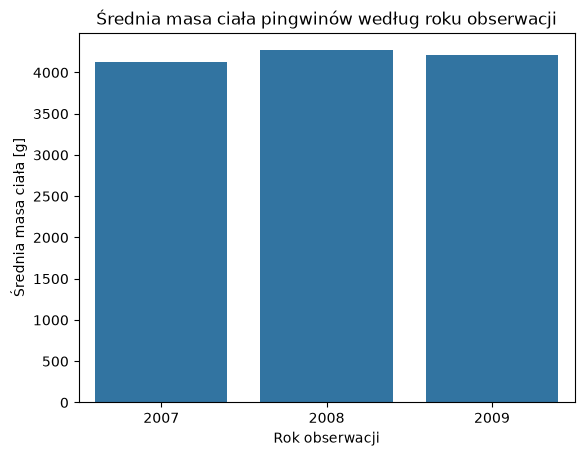

In [56]:
pipeline = [
    {"$group": {"_id": "$year", "avg_mass": {"$avg": "$body_mass_g"}}},
    {"$sort": {"_id": 1}}
]
wyniki = pd.DataFrame(penguins.aggregate(pipeline))
wyniki = wyniki.rename(columns={"_id": "year"})
print(wyniki)
 
sns.barplot(data=wyniki, x="year", y="avg_mass")
plt.xlabel("Rok obserwacji")
plt.ylabel("Średnia masa ciała [g]")
plt.title("Średnia masa ciała pingwinów według roku obserwacji")
plt.show()